In [ ]:
# IMPORT

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score, f1_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)
import random, tensorflow as tf
import keras_tuner as kt

In [4]:
# DATA

from sklearn.datasets import make_moons
X, y = make_moons(n_samples=600, noise=0.35, random_state=42)

In [5]:
# Découpage

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [7]:
# Mettre a l'échelle

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
# Etablir une référence non neuronale

logistique = LogisticRegression(random_state=42)
logistique.fit(X_train, y_train)
acc_logistique = logistique.score(X_test, y_test)
print(f"Accuracy référence logistique : {acc_logistique:.3f}")

Accuracy référence logistique : 0.842


In [ ]:
# Recherche d'hyperparamètres avec Keras Tuner (pattern TP6)

class MonHyperModele(kt.HyperModel):
    def build(self, hp):
        keras.utils.set_random_seed(42)   # recherche déterministe
        modele = keras.Sequential([keras.Input(shape=(2,))])
        for _ in range(hp.Int("couches", 1, 2)):
            modele.add(layers.Dense(hp.Choice("neurones", [8, 16, 32, 64]),
                                    activation="relu",
                                    kernel_regularizer=regularizers.l2(hp.Choice("l2", [0.0, 1e-4, 1e-3]))))
            modele.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
        modele.add(layers.Dense(1, activation="sigmoid"))
        modele.compile(optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])),
                       loss="binary_crossentropy", metrics=["accuracy"])
        return modele

    def fit(self, hp, modele, *args, **kwargs):
        kwargs["batch_size"] = hp.Choice("batch", [16, 32, 64])
        return modele.fit(*args, **kwargs)

tuner = kt.RandomSearch(MonHyperModele(), objective="val_accuracy", max_trials=20,
                        seed=0, directory="kt_defi_moons", project_name="moons", overwrite=True)
tuner.search(X_train, y_train, validation_split=0.2, epochs=200,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                      restore_best_weights=True)],
             verbose=0)

meilleurs_hp = tuner.get_best_hyperparameters(1)[0].values
print("Meilleurs hyperparamètres :", meilleurs_hp)

Meilleurs hyperparamètres : {'couches': 2, 'neurones': 16, 'l2': 0.001, 'dropout': 0.1, 'lr': 0.001, 'batch': 16}


In [15]:
# Entrainer un réseau avec Keras

# Construire le réseau (fonction factory, pattern du TP5)

def construire(neurones, dropout, l2, lr=1e-3, couches=1, seed=42):
    keras.utils.set_random_seed(seed)
    modele = keras.Sequential([keras.Input(shape=(2,))])
    for _ in range(couches):
        modele.add(layers.Dense(neurones, activation="relu",
                                kernel_regularizer=regularizers.l2(l2)))
        modele.add(layers.Dropout(dropout))
    modele.add(layers.Dense(1, activation="sigmoid"))
    modele.compile(optimizer=keras.optimizers.Adam(lr),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modele

modele = construire(neurones=16, dropout=0.1, l2=0.001, lr=0.001, couches=2, seed=42)
modele.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Entraîner avec EarlyStopping (restore_best_weights=True)

arret = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

historique = modele.fit(
    X_train, y_train,
    validation_split=0.2,   # validation prise DANS le train
    epochs=500,
    batch_size=16,
    callbacks=[arret],
    verbose=0
)
print(f"Époques effectuées : {len(historique.history['loss'])}")

acc_reseau = modele.evaluate(X_test, y_test, verbose=0)[1]
print(f"Accuracy réseau : {acc_reseau:.3f}")

Époques effectuées : 174
Accuracy réseau : 0.883


In [17]:
# Comparer 2 réglages sur 3 graines (pattern TP5)

reglage_A = dict(neurones=16, dropout=0.0, l2=0.0, lr=1e-3, couches=1, batch=32)   # défaut (point 6)
reglage_B = dict(neurones=16, dropout=0.1, l2=1e-3, lr=1e-3, couches=2, batch=16)   # gagnant du tuner

SEEDS = [0, 1, 2]
reglages = {"A — défaut": reglage_A, "B — tuner": reglage_B}

resultats = {}
for nom, reg in reglages.items():
    accuracies = []
    for seed in SEEDS:
        modele = construire(neurones=reg["neurones"], dropout=reg["dropout"],
                            l2=reg["l2"], lr=reg["lr"], couches=reg["couches"], seed=seed)
        arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                              restore_best_weights=True)
        modele.fit(X_train, y_train, validation_split=0.2, epochs=500,
                   batch_size=reg["batch"], callbacks=[arret], verbose=0)
        acc = modele.evaluate(X_test, y_test, verbose=0)[1]
        accuracies.append(acc)
        print(f"{nom} · seed {seed} : accuracy = {acc:.3f}")
    resultats[nom] = np.array(accuracies)
    print()

A — défaut · seed 0 : accuracy = 0.850
A — défaut · seed 1 : accuracy = 0.883
A — défaut · seed 2 : accuracy = 0.883

B — tuner · seed 0 : accuracy = 0.875
B — tuner · seed 1 : accuracy = 0.883
B — tuner · seed 2 : accuracy = 0.892



In [23]:
# Synthèse : moyenne ± écart-type (TP5) et marge de bruit (formule du TP5)

acc_A = resultats["A — défaut"]
acc_B = resultats["B — tuner"]

print(f"Référence logistique : {acc_logistique:.3f}")
print(f"Réglage A (défaut)   : {acc_A.mean():.3f} ± {acc_A.std():.3f}")
print(f"Réglage B (tuner)    : {acc_B.mean():.3f} ± {acc_B.std():.3f}")

Référence logistique : 0.842
Réglage A (défaut)   : 0.872 ± 0.016
Réglage B (tuner)    : 0.883 ± 0.007


In [21]:
modele_final = construire(neurones=reglage_B["neurones"], dropout=reglage_B["dropout"],
                          l2=reglage_B["l2"], lr=reglage_B["lr"],
                          couches=reglage_B["couches"], seed=42)
arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                      restore_best_weights=True)
modele_final.fit(X_train, y_train, validation_split=0.2, epochs=500,
                 batch_size=reglage_B["batch"], callbacks=[arret], verbose=0)

y_pred_logistique = logistique.predict(X_test)
y_pred_reseau = (modele_final.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

acc_reseau = modele_final.evaluate(X_test, y_test, verbose=0)[1]
f1_logistique = f1_score(y_test, y_pred_logistique, average="macro")
f1_reseau = f1_score(y_test, y_pred_reseau, average="macro")

print("                Accuracy   F1 macro")
print(f"Logistique      {acc_logistique:.3f}      {f1_logistique:.3f}")
print(f"Réseau (B)      {acc_reseau:.3f}      {f1_reseau:.3f}")

                Accuracy   F1 macro
Logistique      0.842      0.842
Réseau (B)      0.883      0.883


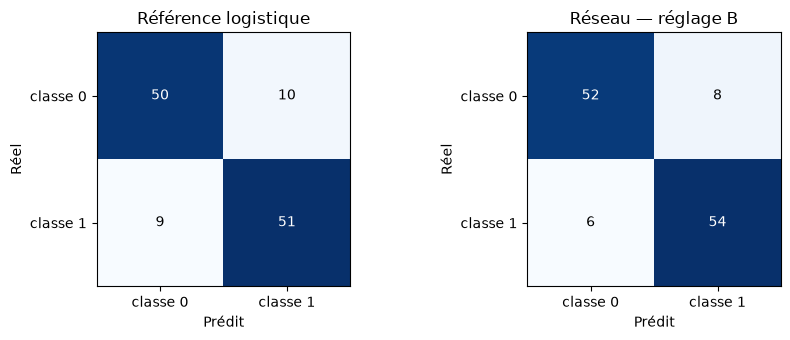

In [22]:
# Matrices de confusion côte à côte

mat_logistique = confusion_matrix(y_test, y_pred_logistique)
mat_reseau = confusion_matrix(y_test, y_pred_reseau)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for axe, mat, titre in [(axes[0], mat_logistique, "Référence logistique"),
                        (axes[1], mat_reseau, "Réseau — réglage B")]:
    axe.imshow(mat, cmap="Blues")
    for i in range(2):
        for j in range(2):
            axe.text(j, i, str(mat[i, j]), ha="center", va="center",
                     color="white" if mat[i, j] > mat.max() / 2 else "black")
    axe.set_xticks([0, 1], ["classe 0", "classe 1"])
    axe.set_yticks([0, 1], ["classe 0", "classe 1"])
    axe.set_xlabel("Prédit")
    axe.set_ylabel("Réel")
    axe.set_title(titre)
plt.tight_layout()
plt.show()

In [24]:
# Marge de bruit : incertitude d'une accuracy mesurée sur n exemples de test
n = len(y_test)
p = acc_logistique
marge_bruit = 1.96 * np.sqrt(p * (1 - p) / n)
print(f"\nMarge de bruit à 95 % (n = {n} exemples de test) : ± {marge_bruit:.3f}")

gain_A = acc_A.mean() - acc_logistique
gain_B = acc_B.mean() - acc_logistique
print(f"Gain A vs logistique : {gain_A:+.3f}")
print(f"Gain B vs logistique : {gain_B:+.3f}")

if gain_B > marge_bruit:
    print("→ Le réglage B dépasse la marge de bruit : gain probablement réel.")
else:
    print("→ Le réglage B ne dépasse pas la marge de bruit : gain non démontré.")


Marge de bruit à 95 % (n = 120 exemples de test) : ± 0.065
Gain A vs logistique : +0.031
Gain B vs logistique : +0.042
→ Le réglage B ne dépasse pas la marge de bruit : gain non démontré.


## Conclusion

### Protocole
Le jeu de données `make_moons` (600 exemples, bruit 0.35) n’est **pas séparable par une droite** : deux croissants imbriqués. Découpage stratifié 480 exemples d’entraînement / 120 exemples de test, standardisation **sans fuite de données** (scaler ajusté sur l’échantillon d’entraînement uniquement). Trois modèles ont été comparés : une **régression logistique** (référence), un réseau **réglage A** (1 couche de 16 neurones) et un réseau **réglage B** choisi par Keras Tuner (2 couches de 16 neurones, dropout 0.1, L2 0.001, lr 0.001, batch 16). Les réseaux utilisent `EarlyStopping(restore_best_weights=True)` sur une validation issue de l’échantillon d’entraînement, et sont comparés sur **3 graines** (moyenne ± écart-type).

### Résultats

| Modèle | Accuracy | F1 macro |
|---|---|---|
| Régression logistique | 0.842 | 0.842 |
| Réseau A — défaut (3 graines) | 0.872 ± 0.016 | — |
| Réseau B — tuner (3 graines) | 0.883 ± 0.007 | 0.883 |

Le F1 macro est égal à l’accuracy : les erreurs sont réparties équitablement entre les deux classes, aucune n’est sacrifiée.

### Analyse
Le gain du meilleur réseau sur la référence est de +0.041 en accuracy. Or la **marge de bruit** à 95 % sur 120 exemples de test vaut ±0.065 : une accuracy mesurée sur ce test peut fluctuer de ±6.5 points par simple hasard d’échantillonnage. Le gain observé (+4 points) est donc inférieur à la marge de bruit : il n’est pas démontré que le réseau soit supérieur à la régression logistique. Seule différence tangible : le réglage B est plus stable entre graines (±0.007 contre ±0.016 pour A) : la régularisation choisie par le tuner a lissé l’entraînement.

### Verdict
Le réseau ne bat pas la logistique de manière démontrée. Pour le client Datalys, il est donc recommandé de conserver la régression logistique : performance équivalente (à la marge de bruit près), modèle plus simple, plus rapide et interprétable. Si trancher entre les deux devenait un vrai enjeu, il faudrait plus de données de test. La marge décroît en 1/√n : 4× plus d’exemples ⇒ marge divisée par 2.